# Лабораторная работа №2


## Подготовка

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [62]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path('/content/drive/MyDrive/LR2_data')

files = [
    'data_train.csv',
    'target_train.csv',
    'data_test_small.csv',
    'target_test_small.csv'
]

for filename in files:
    assert (DATA_DIR / filename).is_file(), f'Не найден файл: {filename}'


In [63]:
import os, time, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.signal import periodogram, detrend
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera, durbin_watson
from statsmodels.tsa.stattools import acf, adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from pathlib import Path
import torch
from torch import nn
from torch.nn import functional as F_torch
from torch.utils.data import DataLoader, TensorDataset
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.set_num_threads(min(2, max(1, os.cpu_count() or 1)))
sns.set_style('whitegrid')
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid':True, 'grid.alpha':0.25})
pd.set_option('display.max_columns', 40)
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
print('Python / PyTorch готовы; CUDA:', torch.cuda.is_available())

Python / PyTorch готовы; CUDA: False


In [64]:
def calc_metrics(y_true, y_pred, mape_floor=1e-2):
    """MAE и RMSE — в единицах таргета; относительные ошибки — в процентах.
    MAPE ниже является MAPE с отсечкой знаменателя, а не стандартной MAPE.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if not (np.isfinite(y_true).all() and np.isfinite(y_pred).all()):
        raise ValueError('В метриках встретились NaN/inf; проверьте подготовку признаков.')
    e = y_true - y_pred
    return {
        'MAE': float(np.mean(np.abs(e))),
        'RMSE': float(np.sqrt(np.mean(e**2))),
        'MAPE_eps, %': float(100 * np.mean(np.abs(e) / np.maximum(np.abs(y_true), mape_floor))),
        'WAPE, %': float(100 * np.sum(np.abs(e)) / max(np.sum(np.abs(y_true)), 1e-12)),
        'R2': float(r2_score(y_true, y_pred)),
    }


def direction_scores(y_true, y_pred, y_base):
    """Направление изменения относительно последнего доступного анализа."""
    yt, yp, yb = map(np.asarray, (y_true, y_pred, y_base))
    actual = np.sign(yt - yb)
    predicted = np.sign(yp - yb)
    moving = actual != 0
    predicted_moving = predicted != 0
    accuracy = np.mean(actual[moving] == predicted[moving]) if moving.any() else np.nan
    precision = np.mean(actual[predicted_moving] == predicted[predicted_moving]) if predicted_moving.any() else np.nan
    return float(accuracy), float(precision), int(moving.sum())


def fmt_table(rows, index_name):
    out = pd.DataFrame(rows).T
    out.index.name = index_name
    return out.round(4)


## 2.1. EDA

Начнём с проверки самих таблиц. Для временного ряда важно не только распределение значений, но и когда они были измерены. Отдельно смотрим регулярные минутные датчики и редкие каналы, иначе нормальную периодичность измерений можно ошибочно принять за поломку.

In [65]:
# Загрузка четырёх файлов задания
data_train_raw = pd.read_csv(DATA_DIR / 'data_train.csv', parse_dates=['datetime'])
target_train_raw = pd.read_csv(DATA_DIR / 'target_train.csv', parse_dates=['Дата'])
data_test_raw = pd.read_csv(DATA_DIR / 'data_test_small.csv', parse_dates=['datetime'])
target_test_raw = pd.read_csv(DATA_DIR / 'target_test_small.csv', parse_dates=['Дата'])

ALL_TELEM = [f'telemetry_{i}' for i in range(16)]
TELEM_MIN = [f'telemetry_{i}' for i in range(12)]   # «минутные» каналы
TELEM_SPARSE = [f'telemetry_{i}' for i in range(12, 16)]  # редкие (2-часовые) каналы

summary = pd.DataFrame({
    'Файл': ['data_train.csv', 'target_train.csv', 'data_test_small.csv', 'target_test_small.csv'],
    'Строк': [len(data_train_raw), len(target_train_raw), len(data_test_raw), len(target_test_raw)],
    'Начало': [data_train_raw.datetime.min(), target_train_raw['Дата'].min(),
               data_test_raw.datetime.min(), target_test_raw['Дата'].min()],
    'Конец': [data_train_raw.datetime.max(), target_train_raw['Дата'].max(),
              data_test_raw.datetime.max(), target_test_raw['Дата'].max()],
})
display(summary)
print('Колонки телеметрии:', list(data_train_raw.columns))
display(data_train_raw.head(3))
display(target_train_raw.head(3))

,Файл,Строк,Начало,Конец
0,data_train.csv,319546,2019-03-01 00:01:00,2019-10-07 19:58:00
1,target_train.csv,1773,2019-03-13 17:00:00,2019-10-07 21:00:00
2,data_test_small.csv,39943,2019-10-07 19:59:00,2019-11-04 10:25:00
3,target_test_small.csv,318,2019-10-07 23:00:00,2019-11-04 09:00:00


Колонки телеметрии: ['datetime', 'telemetry_0', 'telemetry_1', 'telemetry_2', 'telemetry_3', 'telemetry_4', 'telemetry_5', 'telemetry_6', 'telemetry_7', 'telemetry_8', 'telemetry_9', 'telemetry_10', 'telemetry_11', 'telemetry_12', 'telemetry_13', 'telemetry_14', 'telemetry_15']


,datetime,telemetry_0,telemetry_1,telemetry_2,telemetry_3,telemetry_4,telemetry_5,telemetry_6,telemetry_7,telemetry_8,telemetry_9,telemetry_10,telemetry_11,telemetry_12,telemetry_13,telemetry_14,telemetry_15
0,2019-03-01 00:01:00,0.737538,0.478367,0.292816,0.644016,0.919471,0.884814,0.754800,0.413295,0.47192,0.677801,0.687535,0.498407,NaN,NaN,NaN,NaN
1,2019-03-01 00:02:00,0.738406,0.478977,0.292816,0.648557,0.919471,0.887129,0.752977,0.413295,0.47192,0.677801,0.688926,0.498407,NaN,NaN,NaN,NaN
2,2019-03-01 00:03:00,0.738985,0.478977,0.292816,0.647164,0.919471,0.887129,0.755444,0.413295,0.47192,0.677801,0.690316,0.498407,NaN,NaN,NaN,NaN


,Дата,target
0,2019-03-13 17:00:00,0.123711
1,2019-03-13 21:00:00,0.319588
2,2019-03-14 01:00:00,0.255155


In [66]:
# Сводка качества сырых данных
quality = []
for name, df, tcol in [('train', data_train_raw, 'datetime'), ('test', data_test_raw, 'datetime')]:
    dup = int(df[tcol].duplicated().sum())
    full_grid = pd.date_range(df[tcol].min(), df[tcol].max(), freq='min')
    quality.append({
        'Выборка': name,
        'Строк': len(df),
        'Уникальных минут': df[tcol].nunique(),
        'Дубликатов метки': dup,
        'Минут в полном диапазоне': len(full_grid),
        'Пропущено минут': len(full_grid) - df[tcol].nunique(),
        'NaN по каналам (сумма)': int(df[ALL_TELEM].isna().sum().sum()),
    })
display(pd.DataFrame(quality).set_index('Выборка'))

print('\nПропуски по каналам (train):')
na_share = (data_train_raw[ALL_TELEM].isna().mean() * 100).round(2)
display(na_share.rename('NaN, %').to_frame().T)

# Физический диапазон значений каналов
print('Каналы вне диапазона [0, 1]:',
      [c for c in ALL_TELEM if ((data_train_raw[c] < 0) | (data_train_raw[c] > 1)).any()] or 'нет')
print('Диапазон таргета: [%.4f; %.4f], нулевых значений: %d'
      % (target_train_raw.target.min(), target_train_raw.target.max(),
         int((target_train_raw.target == 0).sum())))

,Строк,Уникальных минут,Дубликатов метки,Минут в полном диапазоне,Пропущено минут,NaN по каналам (сумма)
Выборка,,,,,,
train,319546,317998,1548,317998,0,1270103
test,39943,39747,196,39747,0,158512



Пропуски по каналам (train):


,telemetry_0,telemetry_1,telemetry_2,telemetry_3,telemetry_4,telemetry_5,telemetry_6,telemetry_7,telemetry_8,telemetry_9,telemetry_10,telemetry_11,telemetry_12,telemetry_13,telemetry_14,telemetry_15
"NaN, %",0.01,0.01,0.01,0.01,0.04,0.01,0.01,0.01,0.01,0.01,0.01,0.01,99.34,99.34,99.34,99.34


Каналы вне диапазона [0, 1]: нет
Диапазон таргета: [0.0000; 0.7165], нулевых значений: 1


### Тренды и сезонность телеметрии

Сначала посмотрим на изменения рабочих уровней за несколько месяцев, затем — на суточный профиль и спектр. Наличие пика на периодограмме само по себе ещё не доказывает устойчивую сезонность: на спектр влияют режимы работы и тренд.

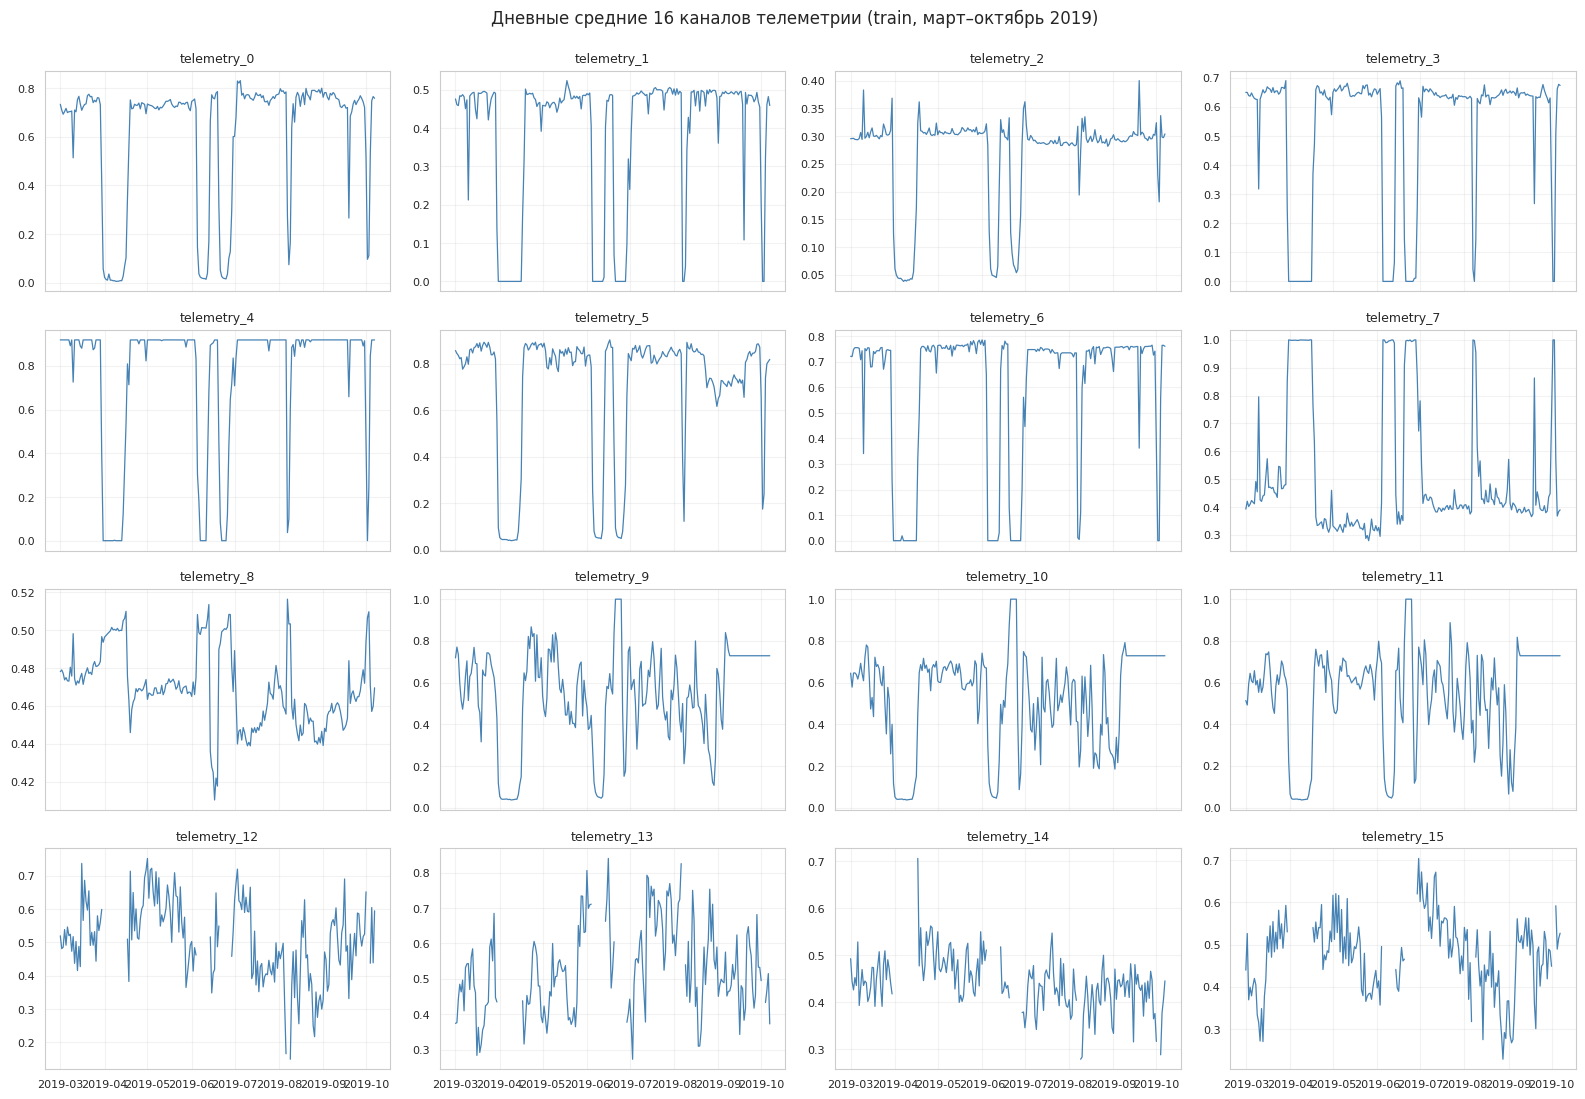

In [67]:
# Динамика 16 каналов: дневные средние за 8 месяцев
tel_train = data_train_raw.set_index('datetime')[ALL_TELEM]
tel_daily = tel_train.resample('D').mean()

fig, axes = plt.subplots(4, 4, figsize=(16, 11), sharex=True)
for ax, c in zip(axes.ravel(), ALL_TELEM):
    ax.plot(tel_daily.index, tel_daily[c], lw=0.9, color='steelblue')
    ax.set_title(c, fontsize=9)
    ax.tick_params(labelsize=8)
fig.suptitle('Дневные средние 16 каналов телеметрии (train, март–октябрь 2019)', y=0.995, fontsize=12)
plt.tight_layout()
plt.show()

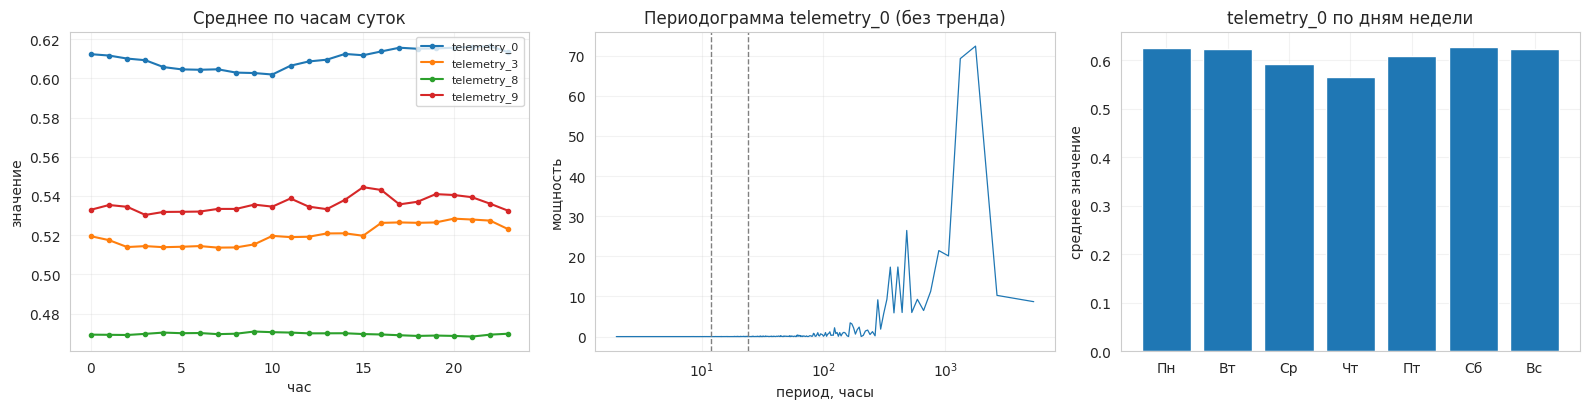

Размах суточного профиля / стандартное отклонение:
  telemetry_0: 0.052
  telemetry_3: 0.057
  telemetry_8: 0.115
  telemetry_9: 0.056


In [68]:
# Суточный профиль и периодограмма. Спектр считаем после удаления линейного тренда.
hourly = tel_train.resample('h').mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for c in ['telemetry_0', 'telemetry_3', 'telemetry_8', 'telemetry_9']:
    prof = hourly[c].groupby(hourly.index.hour).mean()
    axes[0].plot(prof.index, prof.values, marker='.', label=c)
axes[0].set(title='Среднее по часам суток', xlabel='час', ylabel='значение')
axes[0].legend(fontsize=8)
s = hourly['telemetry_0'].interpolate(limit=2).dropna().to_numpy()
f, power = periodogram(detrend(s), fs=1.0)
axes[1].semilogx(1 / f[1:], power[1:], lw=.9)
for p in [12, 24]:
    axes[1].axvline(p, color='gray', ls='--', lw=1)
axes[1].set(title='Периодограмма telemetry_0 (без тренда)', xlabel='период, часы', ylabel='мощность')
dow = hourly['telemetry_0'].groupby(hourly.index.dayofweek).mean()
axes[2].bar(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'], dow.values)
axes[2].set(title='telemetry_0 по дням недели', ylabel='среднее значение')
plt.tight_layout()
plt.show()
print('Размах суточного профиля / стандартное отклонение:')
for c in ['telemetry_0', 'telemetry_3', 'telemetry_8', 'telemetry_9']:
    prof = hourly[c].groupby(hourly.index.hour).mean()
    print(f'  {c}: {(prof.max()-prof.min()) / hourly[c].std():.3f}')


Поскольку ряды могут менять уровень и дисперсию, проверим их стационарность теми же инструментами, что использовали в первой лабораторной: ADF, KPSS и ACF/PACF. Смысл ADF и KPSS различается, поэтому трактовать их нужно совместно.

,ADF p,KPSS p
канал,,
telemetry_0,0.0052,0.0100
telemetry_3,0.0010,0.0216
telemetry_8,0.0000,0.0100


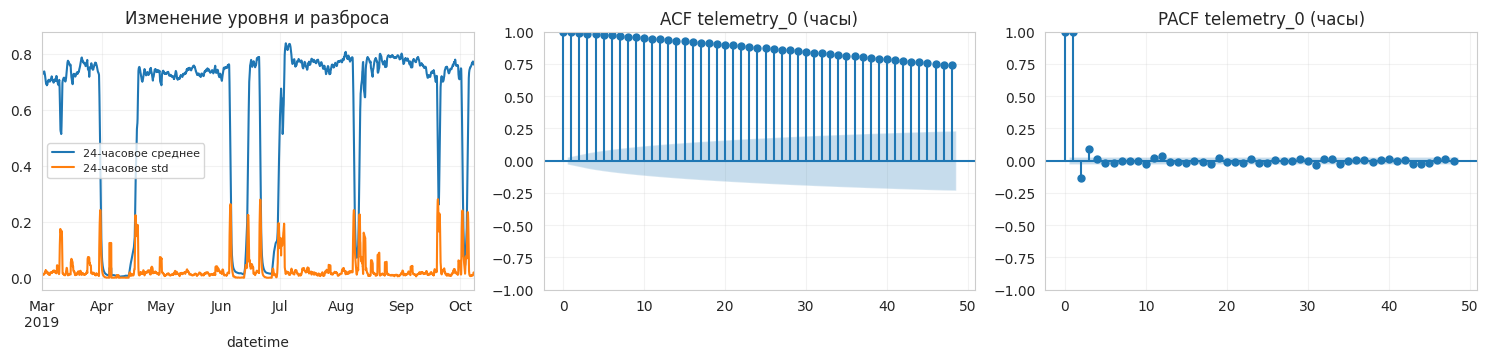

In [69]:
# ADF/KPSS на нескольких типичных каналах, без подгонки результата под ожидания.
stat_rows=[]
for c in ['telemetry_0','telemetry_3','telemetry_8']:
    s=hourly[c].interpolate(limit=2).dropna().astype(float)
    if len(s)<100 or s.std()==0:continue
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            adf_p=float(adfuller(s,autolag='AIC')[1])
            kpss_p=float(kpss(s,regression='c',nlags='auto')[1])
        stat_rows.append({'канал':c,'ADF p':adf_p,'KPSS p':kpss_p})
    except ValueError as exc:
        print('Пропущен',c,':',exc)
display(pd.DataFrame(stat_rows).set_index('канал').round(4))
s=hourly['telemetry_0'].interpolate(limit=2).dropna()
fig,axes=plt.subplots(1,3,figsize=(15,3.7))
s.rolling(24,min_periods=12).mean().plot(ax=axes[0],label='24-часовое среднее')
s.rolling(24,min_periods=12).std().plot(ax=axes[0],label='24-часовое std')
axes[0].set_title('Изменение уровня и разброса');axes[0].legend(fontsize=8)
plot_acf(s,lags=48,ax=axes[1],title='ACF telemetry_0 (часы)')
plot_pacf(s,lags=48,method='ywm',ax=axes[2],title='PACF telemetry_0 (часы)')
plt.tight_layout();plt.show()

### Пропуски, выбросы и взаимосвязи датчиков

Проверка IQR здесь служит диагностике, а не автоматическому удалению редких наблюдений. Для печи необычный уровень сигнала может отражать рабочий переходный режим. Без технологических порогов нельзя заменять его средним.

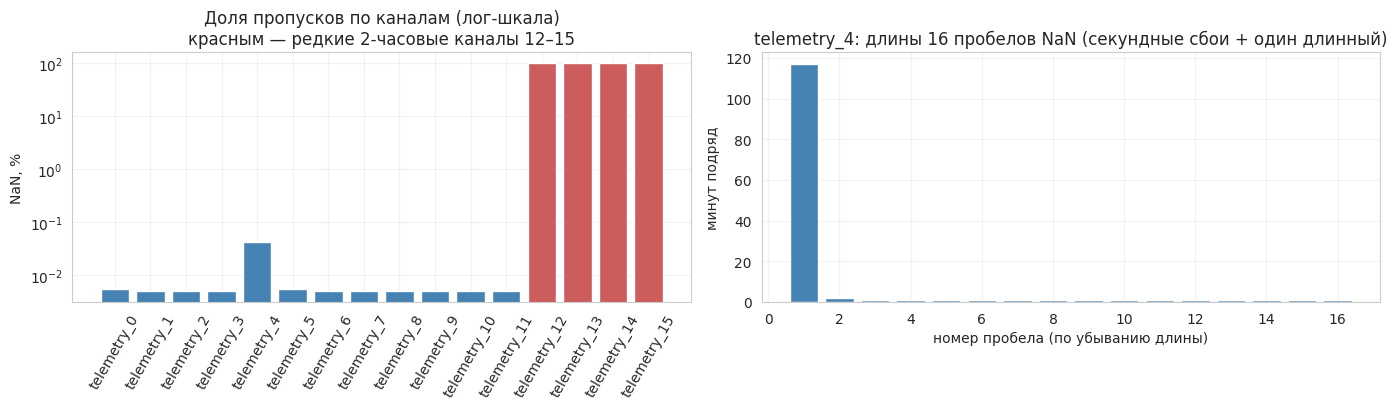

telemetry_4: 14 одиночных пропусков, один пробел длиной 117 мин
Каналы 12–15: число валидных значений = 2098 — измеряются раз в 2 часа (см. п. 2.8)


In [70]:
# Структура пропусков
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

na_pct = (tel_train.isna().mean() * 100)
colors = ['indianred' if c in TELEM_SPARSE else 'steelblue' for c in na_pct.index]
axes[0].bar(na_pct.index, na_pct.values, color=colors)
axes[0].set_yscale('log')
axes[0].set_title('Доля пропусков по каналам (лог-шкала)\nкрасным — редкие 2-часовые каналы 12–15')
axes[0].set_ylabel('NaN, %')
axes[0].tick_params(axis='x', rotation=60)

# Пробеги NaN в telemetry_4
isna = tel_train['telemetry_4'].isna()
runs = isna.groupby((isna != isna.shift()).cumsum()).sum()
runs = runs[runs > 0]
axes[1].bar(range(1, len(runs) + 1), runs.sort_values(ascending=False).values, color='steelblue')
axes[1].set_title(f'telemetry_4: длины {len(runs)} пробелов NaN (секундные сбои + один длинный)')
axes[1].set_xlabel('номер пробела (по убыванию длины)'); axes[1].set_ylabel('минут подряд')
plt.tight_layout()
plt.show()

print(f'telemetry_4: {int(runs[runs == 1].sum())} одиночных пропусков, один пробел длиной {int(runs.max())} мин')
print('Каналы 12–15: число валидных значений =', int(tel_train['telemetry_12'].notna().sum()),
      '— измеряются раз в 2 часа (см. п. 2.8)')

In [71]:
# Выбросы по правилу IQR (k = 2.0) и значения на границах диапазона [0, 1]
rows = []
for c in ALL_TELEM:
    s = tel_train[c].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 2.0 * iqr, q3 + 2.0 * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    rows.append({
        'канал': c, 'min': s.min(), 'max': s.max(),
        'границы IQR': f'[{lo:.3f}; {hi:.3f}]',
        'выбросов, шт': n_out, 'выбросов, %': round(n_out / len(s) * 100, 3),
        '= 0, шт': int((s == 0).sum()), '= 1, шт': int((s == 1).sum()),
    })
display(pd.DataFrame(rows).set_index('канал'))

,min,max,границы IQR,"выбросов, шт","выбросов, %","= 0, шт","= 1, шт"
канал,,,,,,,
telemetry_0,0.003472,1.000000,[0.526; 0.930],66676,20.867,0,53
telemetry_1,0.000000,0.610826,[0.305; 0.620],70850,22.173,65292,0
telemetry_2,0.031828,1.000000,[0.248; 0.342],65611,20.534,0,13
telemetry_3,0.000000,1.000000,[0.536; 0.740],64108,20.063,60195,1
telemetry_4,0.000000,1.000000,[0.919; 0.920],68327,21.391,42422,12
telemetry_5,0.000000,1.000000,[0.423; 1.157],56066,17.546,2,226
telemetry_6,0.000000,1.000000,[0.584; 0.876],69618,21.788,59923,1
telemetry_7,0.020644,1.000000,[0.114; 0.744],69013,21.598,0,37522
telemetry_8,0.344030,1.000000,[0.398; 0.538],990,0.310,0,13


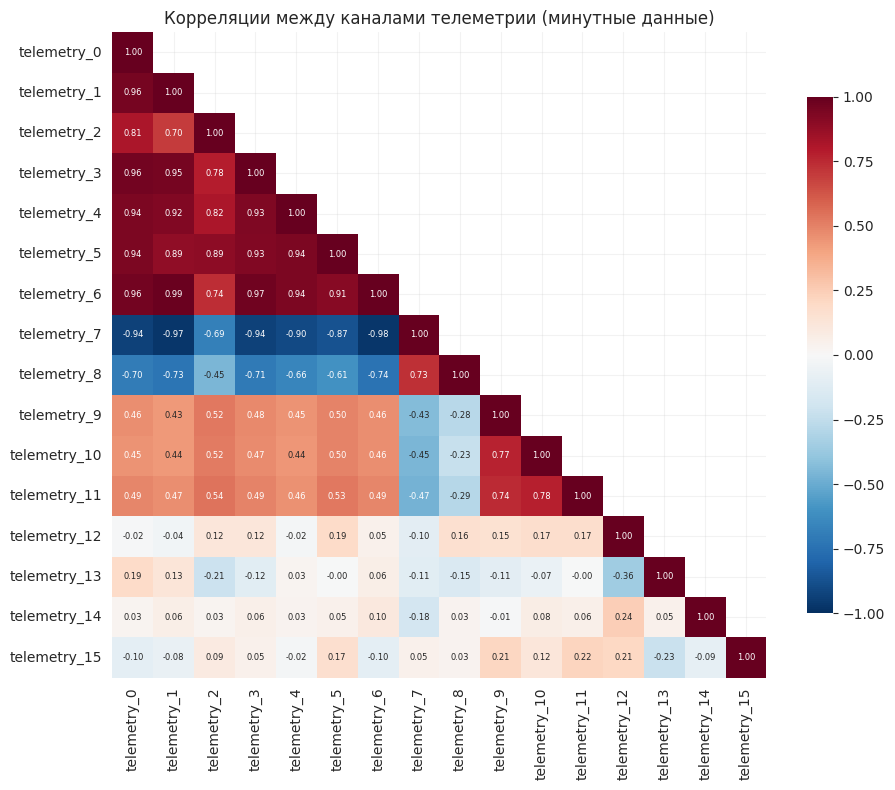

Наиболее коррелированные пары каналов:
telemetry_1  telemetry_6    0.986
telemetry_6  telemetry_7   -0.976
telemetry_3  telemetry_6    0.973
telemetry_1  telemetry_7   -0.971
telemetry_0  telemetry_6    0.965
             telemetry_3    0.962
             telemetry_1    0.958
telemetry_1  telemetry_3    0.954


In [72]:
# Корреляционная матрица 16 каналов (по минутным данным)
corr = tel_train.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, annot_kws={'size': 6}, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Корреляции между каналами телеметрии (минутные данные)')
plt.tight_layout()
plt.show()

# Сильные пары
pairs = (corr.where(mask).stack()).sort_values(key=abs, ascending=False)
print('Наиболее коррелированные пары каналов:')
print(pairs.head(8).round(3).to_string())

### Лабораторный показатель

Проверяем диапазон концентрации, распределение и интервалы между замерами. В отличие от минутных датчиков, лабораторные данные нерегулярны: последовательные пробы не обязаны быть разделены одинаковым числом часов.

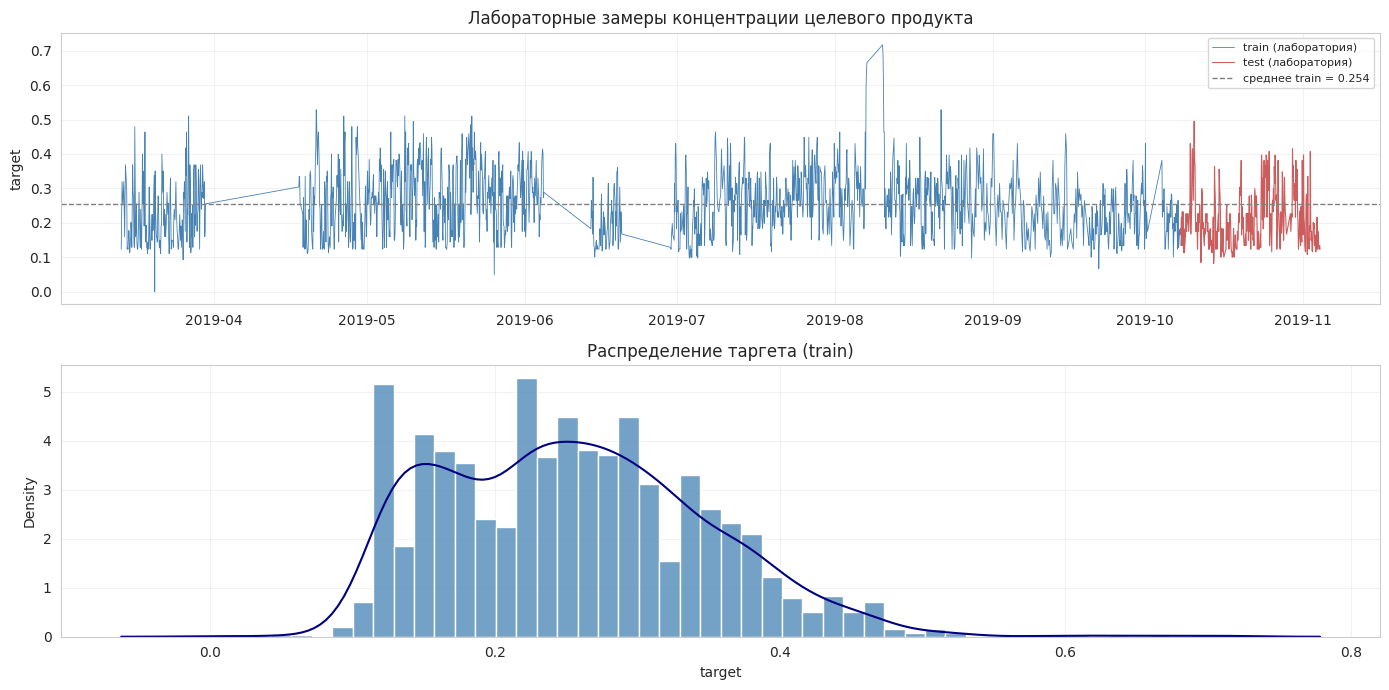

,count,mean,std,min,25%,50%,75%,max
train,1773.0,0.2543,0.0922,0.0000,0.1753,0.2474,0.3144,0.7165
test,318.0,0.2097,0.0805,0.0825,0.1495,0.1946,0.2500,0.4948


In [73]:
# Ряд таргета: train и test
tgt_train = target_train_raw.set_index('Дата')['target'].sort_index()
tgt_test = target_test_raw.set_index('Дата')['target'].sort_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=False)
axes[0].plot(tgt_train.index, tgt_train.values, lw=0.6, color='steelblue', label='train (лаборатория)')
axes[0].plot(tgt_test.index, tgt_test.values, lw=0.8, color='indianred', label='test (лаборатория)')
axes[0].axhline(tgt_train.mean(), color='gray', ls='--', lw=1, label=f'среднее train = {tgt_train.mean():.3f}')
axes[0].set_title('Лабораторные замеры концентрации целевого продукта')
axes[0].set_ylabel('target'); axes[0].legend(fontsize=8)

sns.histplot(tgt_train, bins=50, color='steelblue', stat='density', ax=axes[1], label='train')
sns.kdeplot(tgt_train, color='navy', ax=axes[1])
axes[1].set_title('Распределение таргета (train)'); axes[1].set_xlabel('target')
plt.tight_layout()
plt.show()

display(tgt_train.describe().round(4).to_frame('train').join(tgt_test.describe().round(4).to_frame('test')).T)

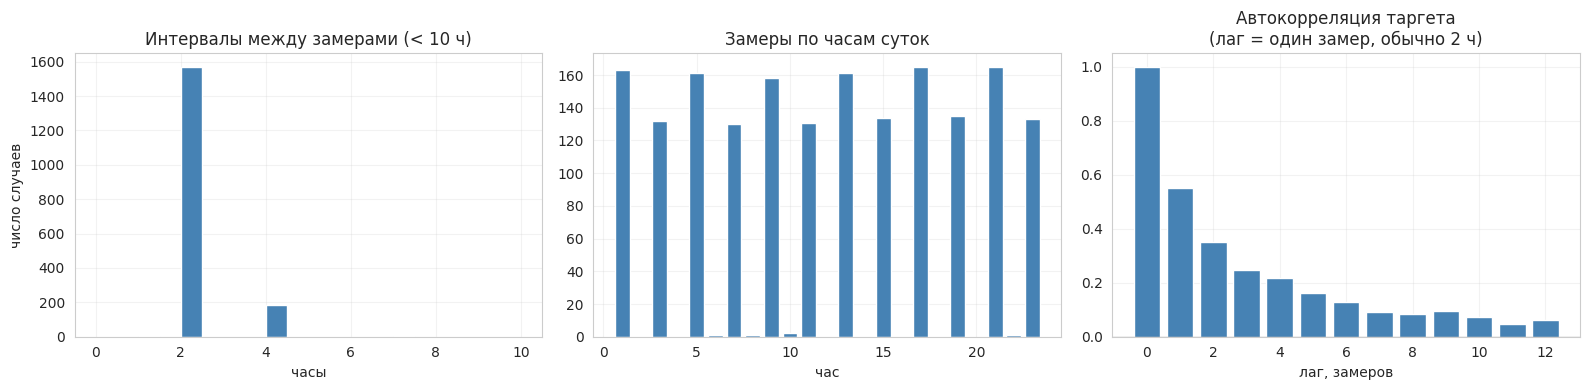

Интервалы между замерами (ч): медиана = 2.0, 95-й перцентиль = 4.0, максимум = 440.5
Доля замеров с интервалом 2 ч: 88.6%
Автокорреляция: лаг 1 = 0.55, лаг 2 = 0.35, лаг 12 (≈ сутки) = 0.06
День недели: замеров Сб/Вс = 547 из 1773


In [74]:
# Частота и регулярность лабораторных замеров
gaps_h = tgt_train.index.to_series().diff().dt.total_seconds() / 3600

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(gaps_h.dropna()[gaps_h < 10], bins=np.arange(0, 10.5, 0.5), color='steelblue', edgecolor='white')
axes[0].set_title('Интервалы между замерами (< 10 ч)')
axes[0].set_xlabel('часы'); axes[0].set_ylabel('число случаев')

hours = tgt_train.index.hour.value_counts().sort_index()
axes[1].bar(hours.index, hours.values, color='steelblue')
axes[1].set_title('Замеры по часам суток'); axes[1].set_xlabel('час')

acf_vals = acf(tgt_train.values, nlags=12)
axes[2].bar(range(13), acf_vals, color='steelblue')
axes[2].axhline(0, color='black', lw=0.8)
axes[2].set_title('Автокорреляция таргета\n(лаг = один замер, обычно 2 ч)')
axes[2].set_xlabel('лаг, замеров')
plt.tight_layout()
plt.show()

print(f'Интервалы между замерами (ч): медиана = {gaps_h.median():.1f}, '
      f'95-й перцентиль = {gaps_h.quantile(0.95):.1f}, максимум = {gaps_h.max():.1f}')
print(f'Доля замеров с интервалом 2 ч: {(gaps_h == 2).mean() * 100:.1f}%')
print(f'Автокорреляция: лаг 1 = {acf_vals[1]:.2f}, лаг 2 = {acf_vals[2]:.2f}, лаг 12 (≈ сутки) = {acf_vals[12]:.2f}')
print('День недели: замеров Сб/Вс =', int(tgt_train.index.dayofweek.isin([5, 6]).sum()),
      'из', len(tgt_train))

### Синхронизация и временные корреляции

Повторы временной метки проверяем на противоречия, затем усредняем значения в пределах одной минуты. Для корреляций сопоставляем значение концентрации с телеметрией того же момента или более ранней. Это описательная связь, а не доказательство физической причинности.

In [75]:
# Повторяющиеся метки не обязательно означают идентичные показания.
mask = data_train_raw.datetime.duplicated(keep=False)
dups = data_train_raw.loc[mask]
nunique = dups.groupby('datetime')[ALL_TELEM].nunique(dropna=False)
conflicted = nunique.gt(1).any(axis=1)
print('Групп повторяющихся минут:', len(nunique))
print('Групп с конфликтующими показаниями:', int(conflicted.sum()))
print('Максимальное число разных значений одного канала:', (int(nunique.max().max()) if len(nunique) else 0))
if conflicted.any():
    delta = dups.groupby('datetime')[ALL_TELEM].agg(lambda s: s.max() - s.min())
    print('Наибольшее расхождение в одной минуте:', float(delta.max().max()))
print('Для одновременных записей берём среднее; это допущение, а не доказательство тождественности.')
tel_train_dedup = data_train_raw.set_index('datetime').groupby(level=0)[ALL_TELEM].mean().sort_index()
tel_test_dedup = data_test_raw.set_index('datetime').groupby(level=0)[ALL_TELEM].mean().sort_index()

# На границе файлов последняя лабораторная точка train не обязана совпадать с концом train-телеметрии.
for name, tel, target in [('train', tel_train_dedup, tgt_train), ('test', tel_test_dedup, tgt_test)]:
    pos = tel.index.get_indexer(target.index, method='pad')
    ok = pos >= 0
    delta_sec = np.full(len(pos), np.inf)
    delta_sec[ok] = (target.index[ok] - tel.index[pos[ok]]).total_seconds()
    print(f'{name}: близкая предшествующая телеметрия (<=2 мин) у '
          f'{int(np.sum(delta_sec <= 120))} из {len(target)} замеров; '
          f'максимальное расстояние {np.nanmax(delta_sec[np.isfinite(delta_sec)]):.0f} с')


Групп повторяющихся минут: 222
Групп с конфликтующими показаниями: 1
Максимальное число разных значений одного канала: 2
Наибольшее расхождение в одной минуте: 0.24000000000000027
Для одновременных записей берём среднее; это допущение, а не доказательство тождественности.
train: близкая предшествующая телеметрия (<=2 мин) у 1772 из 1773 замеров; максимальное расстояние 3720 с
test: близкая предшествующая телеметрия (<=2 мин) у 318 из 318 замеров; максимальное расстояние 0 с


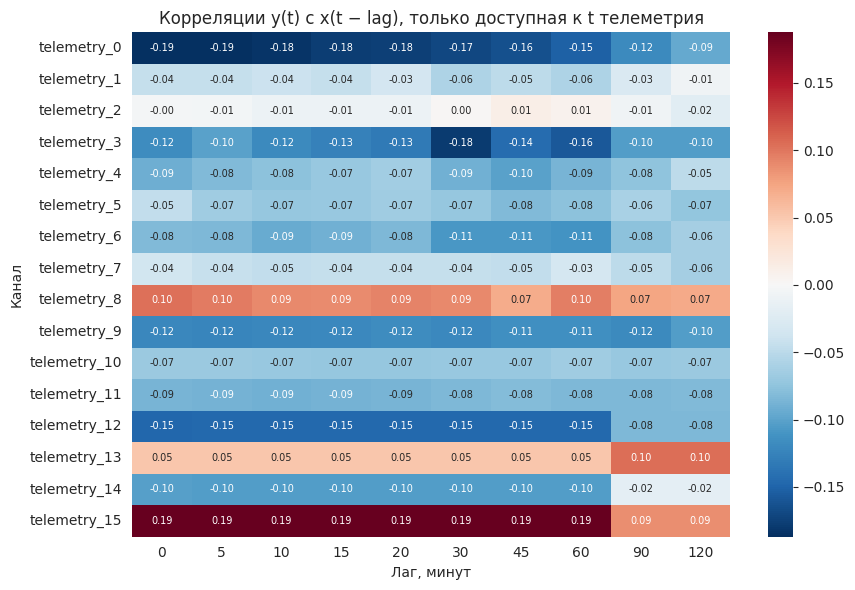

Замеров для кросс-корреляций: 1772 из 1773
telemetry_0: лаг   0 мин, r=-0.187
telemetry_1: лаг  60 мин, r=-0.058
telemetry_2: лаг 120 мин, r=-0.021
telemetry_3: лаг  30 мин, r=-0.179
telemetry_4: лаг  45 мин, r=-0.101
telemetry_5: лаг  45 мин, r=-0.082
telemetry_6: лаг  60 мин, r=-0.112
telemetry_7: лаг 120 мин, r=-0.063
telemetry_8: лаг   0 мин, r=+0.104
telemetry_9: лаг   5 мин, r=-0.123
telemetry_10: лаг  15 мин, r=-0.072
telemetry_11: лаг  10 мин, r=-0.090
telemetry_12: лаг   0 мин, r=-0.148
telemetry_13: лаг  90 мин, r=+0.104
telemetry_14: лаг  45 мин, r=-0.104
telemetry_15: лаг  45 мин, r=+0.188


In [76]:
# Для EDA берём только те замеры, которым соответствует телеметрия не позже самой пробы.
LAGS = [0, 5, 10, 15, 20, 30, 45, 60, 90, 120]
eda_grid = pd.date_range(tel_train_dedup.index.min(), tel_train_dedup.index.max(), freq='min')
tel_cc = tel_train_dedup.reindex(eda_grid).copy()
tel_cc[TELEM_SPARSE] = tel_cc[TELEM_SPARSE].ffill()
lab_eda = tgt_train.loc[(tgt_train.index >= eda_grid.min()) & (tgt_train.index <= eda_grid.max())]
lag_matrix = {}
for c in ALL_TELEM:
    for lag in LAGS:
        aligned = tel_cc[c].shift(lag).reindex(lab_eda.index, method='pad', tolerance=pd.Timedelta(minutes=2))
        lag_matrix[c, lag] = aligned.to_numpy(dtype=float)
xc = pd.DataFrame(index=ALL_TELEM, columns=LAGS, dtype=float)
for c in ALL_TELEM:
    for lag in LAGS:
        x = lag_matrix[c, lag]
        good = np.isfinite(x) & np.isfinite(lab_eda.to_numpy())
        xc.loc[c, lag] = np.corrcoef(x[good], lab_eda.to_numpy()[good])[0, 1] if good.sum() >= 30 and np.std(x[good]) > 0 else np.nan
plt.figure(figsize=(9, 6))
sns.heatmap(xc, annot=True, fmt='.2f', cmap='RdBu_r', center=0, annot_kws={'size': 7})
plt.title('Корреляции y(t) с x(t − lag), только доступная к t телеметрия')
plt.xlabel('Лаг, минут'); plt.ylabel('Канал')
plt.tight_layout(); plt.show()
print('Замеров для кросс-корреляций:', len(lab_eda), 'из', len(tgt_train))
for c in ALL_TELEM:
    valid = xc.loc[c].abs().dropna()
    if not valid.empty:
        lag = int(valid.idxmax())
        print(f'{c}: лаг {lag:>3} мин, r={xc.loc[c, lag]:+.3f}')


Число измерений каналов 12–15: 2097
Шаг между измерениями, ч: медиана = 2.0
Часы измерений: [0, 2, 4, 6, 8, 10, 12, 14, 16, 17, 18, 20, 22]
Часы лабораторных замеров таргета: [1, 3, 5, 6, 7, 8, 9, 10, 11, 13, 15, 17, 19, 21, 22, 23]

Возраст последнего измерения каналов 12–15 в моменты замеров таргета, мин: медиана = 60, макс = 660


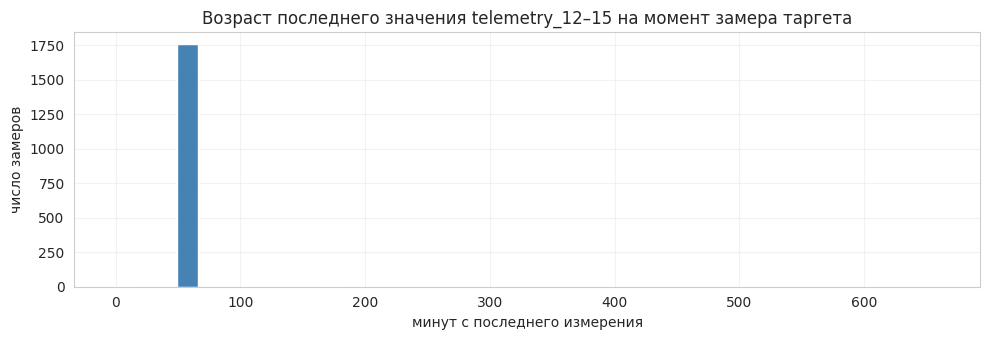

In [77]:
# Сетка измерений редких каналов
sp = tel_train_dedup[TELEM_SPARSE].dropna(how='all')
print('Число измерений каналов 12–15:', len(sp))
print('Шаг между измерениями, ч: медиана =',
      round(sp.index.to_series().diff().dt.total_seconds().div(3600).median(), 1))
print('Часы измерений:', sorted(set(sp.index.hour)))
print('Часы лабораторных замеров таргета:', sorted(set(tgt_train.index.hour)))

# Возраст последнего значения редкого канала в моменты замеров таргета
pos_sp = tel_train_dedup.index.get_indexer(tgt_train.index, method='nearest')
age = []
for t in tgt_train.index:
    valid = sp.index[sp.index <= t]
    age.append((t - valid[-1]).total_seconds() / 60 if len(valid) else np.nan)
age = pd.Series(age)
print(f'\nВозраст последнего измерения каналов 12–15 в моменты замеров таргета, мин: '
      f'медиана = {age.median():.0f}, макс = {age.max():.0f}')

plt.figure(figsize=(10, 3.5))
plt.hist(age.dropna(), bins=40, color='steelblue', edgecolor='white')
plt.title('Возраст последнего значения telemetry_12–15 на момент замера таргета')
plt.xlabel('минут с последнего измерения'); plt.ylabel('число замеров')
plt.tight_layout()
plt.show()

**Выводы** Данные содержат регулярную минутную телеметрию, несколько медленно обновляющихся каналов и гораздо более редкие лабораторные пробы. Характерные рабочие уровни меняются во времени, а часть пропусков связана с периодичностью измерений. Поэтому короткие сбои будем заполнять прошлым значением; длительные не станем скрывать интерполяцией. Для редких каналов укажем возраст последнего измерения. Показания, выходящие за статистические IQR-границы, автоматически удалять не будем.

## 2.2. Признаки временных рядов

Для табличных моделей нужны величины, отражающие историю процесса. Используем лаги 5–240 минут, средние и стандартные отклонения по нескольким окнам, минимумы и максимумы, разности и сглаженное среднее. ffill ограничивается пятью минутами для обычных каналов; четыре редких канала сохраняют прошлое измерение вместе с его возрастом. Лабораторный результат появляется в признаках не раньше 15 минут после отбора пробы.

In [78]:
# Историю минутных показаний объединяем сквозь границу файлов: в момент t
# доступны значения с временными метками не позже t.
tel_all = pd.concat([data_train_raw, data_test_raw], ignore_index=True)
tel_all['datetime'] = pd.to_datetime(tel_all['datetime'])
tel_all = tel_all.groupby('datetime')[ALL_TELEM].mean().sort_index()
grid = pd.date_range(tel_all.index.min(), tel_all.index.max(), freq='min')
tel_all = tel_all.reindex(grid)
minute_age = {}
for c in TELEM_MIN:
    s = tel_all[c]
    last_seen = pd.Series(grid, index=grid).where(s.notna()).ffill()
    minute_age[c] = (pd.Series(grid, index=grid) - last_seen).dt.total_seconds().div(60)
    # В онлайне мы не знаем, сколько продлится пропуск. Поэтому допустимо
    # переносить последнюю точку только первые пять минут пропуска.
    tel_all[c] = s.ffill(limit=5)
print('Минут в общей сетке:', len(grid))
print('Политика NaN: до пяти минут переносим прошлое значение; дальше оставляем NaN.')


Минут в общей сетке: 357745
Политика NaN: до пяти минут переносим прошлое значение; дальше оставляем NaN.


In [79]:
# Учитываем прошлые значения, диапазоны колебаний и скорость изменения показателей.
# Все скользящие окна заканчиваются текущей минутой — будущие точки не используются.
t0 = time.time()
F = pd.DataFrame(index=grid)
LAGS = [5, 15, 30, 60, 120, 240]
WINS = [15, 60, 240]
for c in TELEM_MIN:
    s = tel_all[c]
    F[c] = s
    for lag in LAGS:
        F[f'{c}_lag{lag}'] = s.shift(lag)
    for window in WINS:
        r = s.rolling(window, min_periods=max(3, window // 3))
        F[f'{c}_rmean{window}'] = r.mean()
        F[f'{c}_rstd{window}'] = r.std()
        F[f'{c}_rmin{window}'] = r.min()
        F[f'{c}_rmax{window}'] = r.max()
    F[f'{c}_diff5'] = s.diff(5)
    F[f'{c}_diff60'] = s.diff(60)
    # Относительный темп за час. Порог в знаменателе не даёт малым
    # значениям датчика превращать безобидную разницу в огромный процент.
    prev60 = s.shift(60)
    F[f'{c}_rate60'] = ((s - prev60) / prev60.abs().clip(lower=0.05)).clip(-5, 5)
    F[f'{c}_ewma30'] = s.ewm(halflife=30, min_periods=10).mean()
    F[f'{c}_age'] = minute_age[c].clip(upper=24*60)
print(f'Признаков минутных каналов: {F.shape[1]}; построение {time.time()-t0:.1f} с')

Признаков минутных каналов: 288; построение 2.8 с


In [80]:
# Редко измеряемые каналы нельзя трактовать как неисправные минутные датчики.
# Для каждого канала сохраняем последний известный результат и его возраст.
for c in TELEM_SPARSE:
    s = tel_all[c]
    F[c] = s.ffill()
    last_seen = pd.Series(grid, index=grid).where(s.notna()).ffill()
    F[f'{c}_age'] = (pd.Series(grid, index=grid)-last_seen).dt.total_seconds().div(60).clip(upper=7*24*60)
F['hour_sin'] = np.sin(2 * np.pi * grid.hour / 24)
F['hour_cos'] = np.cos(2 * np.pi * grid.hour / 24)
F['dow_sin'] = np.sin(2 * np.pi * grid.dayofweek / 7)
F['dow_cos'] = np.cos(2 * np.pi * grid.dayofweek / 7)
print('Признаков до учёта истории лаборатории:', F.shape[1])


Признаков до учёта истории лаборатории: 300


In [81]:
DELAY = 15
tgt_all = pd.concat([target_train_raw.assign(is_test=0),
                     target_test_raw.assign(is_test=1)], ignore_index=True)
tgt_all['ts'] = pd.to_datetime(tgt_all['Дата'])
tgt_all = tgt_all.sort_values(['ts','is_test'])
conflicting_split = tgt_all.groupby('ts').is_test.nunique().gt(1)
assert not conflicting_split.any(), 'Одинаковые timestamps обнаружены и в train, и в test.'
n_dup = int(tgt_all.ts.duplicated().sum())
if n_dup:
    print('Повторных лабораторных timestamps:', n_dup, '(усредняем значения внутри одного периода).')
tgt_all = tgt_all.groupby('ts', sort=True).agg({'target':'mean','is_test':'first'})
avail_ts = tgt_all.index + pd.Timedelta(minutes=DELAY)
y_avail = pd.Series(tgt_all.target.to_numpy(),index=avail_ts)
uni = grid.union(avail_ts).sort_values()
last_val = y_avail.reindex(uni).ffill().reindex(grid)
prev_val = y_avail.shift(1).reindex(uni).ffill().reindex(grid)
last_ts = pd.Series(avail_ts,index=avail_ts).reindex(uni).ffill().reindex(grid)
F['tgt_last'] = last_val
F['tgt_prev'] = prev_val
F['tgt_age'] = (pd.Series(grid,index=grid) - last_ts).dt.total_seconds().div(60)
F['tgt_trend'] = last_val-prev_val
F['tgt_last_diff'] = last_val.diff()
print('Всего признаков:', F.shape[1])
assert (F.tgt_age.dropna() >= 0).all(), 'Использовано ещё не доступное лабораторное значение.'
print('Самоконтроль: возраст доступного лабораторного результата неотрицательный.')


Всего признаков: 305
Самоконтроль: возраст доступного лабораторного результата неотрицательный.


In [82]:
# Строка с таргетом в t получает признаки не позже t.
# В отличие от nearest здесь никогда не выбирается будущая минута.
pos = F.index.get_indexer(tgt_all.index, method='pad')
ok = pos >= 0
age_sec = np.full(len(pos),np.inf)
age_sec[ok] = (tgt_all.index[ok]-F.index[pos[ok]]).total_seconds()
# Проверяем наличие действительно записанной строки телеметрии, а не просто
# даты в искусственно созданной минутной сетке. На этих данных совпадение точное.
recorded_times = pd.DatetimeIndex(pd.concat([
    data_train_raw['datetime'], data_test_raw['datetime']
]).unique()).sort_values()
rec_pos = recorded_times.get_indexer(tgt_all.index, method='pad')
rec_gap = np.full(len(rec_pos), np.inf)
rec_ok = rec_pos >= 0
rec_gap[rec_ok] = (tgt_all.index[rec_ok] - recorded_times[rec_pos[rec_ok]]).total_seconds()
valid = ok & (age_sec <= 120) & rec_ok & (rec_gap <= 120)
print(f'Соответствие меток реальной телеметрии: {valid.sum()} из {len(valid)} (<= 2 мин)')
if not valid.all():
    print('Без пригодной телеметрии исключено:', list(tgt_all.index[~valid][:8]))
X_full = F.iloc[pos[valid]].copy()
X_full.index = tgt_all.index[valid]
y_full = tgt_all.target.to_numpy()[valid]
is_test_full = tgt_all.is_test.to_numpy()[valid].astype(bool)
X_train_df = X_full.loc[~is_test_full].astype('float32')
X_test_df = X_full.loc[is_test_full].astype('float32')
y_train = y_full[~is_test_full]
y_test = y_full[is_test_full]
assert X_train_df.index.max() < X_test_df.index.min(), 'Проверка разбиения train/test не прошла.'
assert not np.isnan(y_train).any() and not np.isnan(y_test).any()
print('Train:',X_train_df.shape,'Test:',X_test_df.shape)
print('Доля пропущенных признаков в train:',round(float(X_train_df.isna().mean().mean()),4))
print('Граница лабораторного train/test:',X_train_df.index.max(), '|',X_test_df.index.min())


Соответствие меток реальной телеметрии: 2091 из 2091 (<= 2 мин)
Train: (1773, 305) Test: (318, 305)
Доля пропущенных признаков в train: 0.0
Граница лабораторного train/test: 2019-10-07 21:00:00 | 2019-10-07 23:00:00


### Подготовка пропусков перед обучением

Отбор признаков и PCA в задании нужны при необходимости. Поскольку основной целью здесь является сравнение трёх изученных моделей, отдельный авторский алгоритм корреляционного отбора не вводим. Лаги, скользящие статистики и возраст измерений остаются интерпретируемыми. Для заполнения оставшихся пропусков используем медиану, рассчитанную только на обучающем периоде каждого фолда. Это не обращается к будущим данным.

In [83]:
class MedianFiller(BaseEstimator, TransformerMixin):
    """Заполняет отсутствующие признаки медианами обучающего периода.
    Использует обычный pandas.fillna, а не отдельный метод отбора признаков.
    """
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = list(X.columns)
        self.medians_ = X.median(numeric_only=True).fillna(0.0)
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return X[self.columns_].fillna(self.medians_).fillna(0.0)

imputer_full = MedianFiller().fit(X_train_df)
FEATURE_COLS = imputer_full.columns_
print('Сохранили все рассчитанные признаки:', len(FEATURE_COLS))
print('Медианы будут определяться заново на каждом обучающем фолде.')


Сохранили все рассчитанные признаки: 305
Медианы будут определяться заново на каждом обучающем фолде.


In [85]:
def make_calendar_folds(times, n_splits=5, delay_minutes=15):
    # Делим по календарю: обучение всегда раньше валидации.
    times = pd.DatetimeIndex(times)
    bounds = pd.date_range(times.min(), times.max(), periods=n_splits+2)
    result = []
    for k in range(n_splits):
        edge = bounds[k+1]
        tr = np.where(times + pd.Timedelta(minutes=delay_minutes) <= edge)[0]
        val = np.where((times >= edge) & ((times <= bounds[k+2]) if k == n_splits-1 else (times < bounds[k+2])))[0]
        if len(tr) < 50 or len(val) < 20:
            raise ValueError('Слишком мало наблюдений для календарного фолда')
        result.append((tr,val))
    return result

cal_folds = make_calendar_folds(X_train_df.index)
print('Число наблюдений по фолдам (train/val):', [(len(a),len(b)) for a,b in cal_folds])
print('Признаков после подготовки:', len(FEATURE_COLS), 'из', X_train_df.shape[1])

Число наблюдений по фолдам (train/val): [(191, 403), (594, 239), (833, 343), (1176, 318), (1494, 279)]
Признаков после подготовки: 305 из 305


**Выводы** Для табличных алгоритмов сформированы признаки состояния и динамики печи. Отбор признаков уменьшает дублирование, сохраняя возможность объяснить, что обозначает каждый оставленный показатель.

## 2.3. Построение трёх моделей

**Random Forest** обучает множество деревьев на табличных признаках и усредняет их результаты. Это понятная базовая нелинейная модель

**XGBoost** последовательно улучшает ансамбль деревьев. Ему передаются те же лаги и скользящие характеристики, что и случайному лесу

**TCN** обрабатывает сразу несколько каналов во временном окне. В практике использовалась библиотека `pytorch_tcn`; здесь причинные свёртки реализованы обычными слоями PyTorch, чтобы ноутбук запускался без отдельной библиотеки. Архитектурный принцип тот же, но это адаптация, а не буквальное копирование реализации из практики

**Почему выбраны данные модели.** VAR/VECM из практики требуют совместных рядов на согласованной временной сетке. N-BEATS и TimeLLM рассчитаны в первую очередь на иной формат прогнозирования регулярных рядов

### Random Forest

In [86]:
RF_PARAMS = dict(n_estimators=100, random_state=RANDOM_STATE, n_jobs=2)
RF_FOLD = []
t0 = time.perf_counter()
for k, (tr, va) in enumerate(cal_folds, 1):
    # Заполнение пропусков рассчитывается только на прошлом периоде.
    filter_k = MedianFiller().fit(X_train_df.iloc[tr], y_train[tr])
    X_tr = filter_k.transform(X_train_df.iloc[tr])
    X_va = filter_k.transform(X_train_df.iloc[va])
    forest = RandomForestRegressor(**RF_PARAMS)
    forest.fit(X_tr, y_train[tr])
    fold_mae = mean_absolute_error(y_train[va], forest.predict(X_va))
    RF_FOLD.append(fold_mae)
    print(f'Random Forest, фолд {k}: MAE = {fold_mae:.4f}')
RF_CV = float(np.mean(RF_FOLD))
RF_CV_TIME = time.perf_counter() - t0
print(f'Random Forest: CV MAE = {RF_CV:.4f}')


Random Forest, фолд 1: MAE = 0.0819
Random Forest, фолд 2: MAE = 0.0623
Random Forest, фолд 3: MAE = 0.0592
Random Forest, фолд 4: MAE = 0.0645
Random Forest, фолд 5: MAE = 0.0574
Random Forest: CV MAE = 0.0651


### XGBoost: нелинейная модель по лагам

Количество деревьев выбираем через внутреннюю раннюю остановку. Внешние временные фолды остаются независимым способом сравнить модели: подбор числа деревьев не должен смотреть на их ответы.

In [87]:
# Число деревьев ищем только внутри обучающей части каждого календарного фолда.
# На внешнем validation-фолде ни медианы, ни ранняя остановка не обучаются.
XGB_PARAMS = dict(n_estimators=600, learning_rate=0.03, max_depth=5,
                  min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
                  reg_lambda=1.0, objective='reg:squarederror',
                  random_state=RANDOM_STATE, n_jobs=2, verbosity=0)
fold_rows, best_iters, xgb_maes = [], [], []
for k, (tr_i, va_i) in enumerate(cal_folds, 1):
    n_eval = max(25, int(0.2 * len(tr_i)))
    inner_fit, inner_val = tr_i[:-n_eval], tr_i[-n_eval:]
    imputer_inner = MedianFiller().fit(X_train_df.iloc[inner_fit], y_train[inner_fit])
    xgb_tmp = XGBRegressor(**XGB_PARAMS, early_stopping_rounds=50, eval_metric='mae')
    xgb_tmp.fit(imputer_inner.transform(X_train_df.iloc[inner_fit]), y_train[inner_fit],
                eval_set=[(imputer_inner.transform(X_train_df.iloc[inner_val]), y_train[inner_val])],
                verbose=False)
    n_best = (int(xgb_tmp.best_iteration) + 1
              if xgb_tmp.best_iteration is not None else XGB_PARAMS['n_estimators'])
    # После выбора n_best обучаемся на ВСЁМ внешнем train-фолде.
    imputer_outer = MedianFiller().fit(X_train_df.iloc[tr_i], y_train[tr_i])
    xgb_outer = XGBRegressor(**{**XGB_PARAMS, 'n_estimators': n_best}).fit(
        imputer_outer.transform(X_train_df.iloc[tr_i]), y_train[tr_i])
    pred = xgb_outer.predict(imputer_outer.transform(X_train_df.iloc[va_i]))
    score = mean_absolute_error(y_train[va_i], pred)
    xgb_maes.append(score); best_iters.append(n_best)
    fold_rows.append({'фолд': k, 'опт. деревьев': n_best, 'MAE внешней валидации': round(score, 4)})
display(pd.DataFrame(fold_rows))
XGB_CV = float(np.mean(xgb_maes))
XGB_N_EST = int(np.clip(np.median(best_iters), 25, XGB_PARAMS['n_estimators']))
XGB_PARAMS_FINAL = {**XGB_PARAMS, 'n_estimators': XGB_N_EST}
print(f'XGBoost CV MAE = {XGB_CV:.4f}; медиана числа деревьев = {XGB_N_EST}')

,фолд,опт. деревьев,MAE внешней валидации
0,1,199,0.0771
1,2,318,0.0623
2,3,211,0.0578
3,4,137,0.0659
4,5,90,0.0575


XGBoost CV MAE = 0.0641; медиана числа деревьев = 199


### TCN: многомерные окна за 24 часа

На каждом шаге окна берём агрегированные значения 12 минутных каналов, полноту их наблюдений, четыре редких канала и возраст их значений, доступную лабораторную историю и время суток. Получается тензор (число проб, 48 шагов, 37 характеристик). 48 шагов по 30 минут — сутки истории. Отсутствующие измерения заполняются при масштабировании по статистикам обучающего фолда.

In [88]:
# Для TCN берём 48 получасовых шагов (24 часа истории) по всем 16 каналам.
SEQ_LEN, STEP = 48, 30
SEQ_TELEM = TELEM_MIN
SEQ_SPARSE = TELEM_SPARSE
SEQ_SPARSE_AGE = [f'{c}_age' for c in SEQ_SPARSE]
SEQ_LAB = ['tgt_last', 'tgt_prev', 'tgt_age']
SEQ_N_FEATURES = len(SEQ_TELEM)*2 + len(SEQ_SPARSE)*2 + len(SEQ_LAB) + 2

# Подготовка векторизованных сумм: окно (s,e] можно получить за O(1).
mpos = pd.Series(np.arange(len(grid)), index=grid)
V = tel_all[SEQ_TELEM].to_numpy(dtype='float64')
okm = np.isfinite(V)
cs = np.vstack([np.zeros(V.shape[1]), np.cumsum(np.where(okm, V, 0.0), axis=0)])
cn = np.vstack([np.zeros(V.shape[1]), np.cumsum(okm, axis=0)])
SPARSE = F[SEQ_SPARSE + SEQ_SPARSE_AGE].to_numpy(dtype='float64')
LAB = F[SEQ_LAB].to_numpy(dtype='float64')

def build_sequence_windows(times):
    """Только прошлое: 48 получасовых интервалов, заканчивающихся моментом пробы."""
    times = pd.DatetimeIndex(times)
    ep = mpos.reindex(times, method='pad').to_numpy()
    if np.isnan(ep.astype(float)).any():
        raise ValueError('Есть проба раньше начала телеметрии')
    W = np.full((len(times), SEQ_LEN, SEQ_N_FEATURES), np.nan, dtype='float32')
    n_min = len(SEQ_TELEM)
    for i, e0 in enumerate(ep.astype(int)):
        ends = np.maximum(e0 - (SEQ_LEN - 1 - np.arange(SEQ_LEN)) * STEP, 0)
        starts = np.maximum(ends - STEP, -1)
        num = cs[ends + 1] - cs[starts + 1]
        den = cn[ends + 1] - cn[starts + 1]
        W[i, :, :n_min] = np.divide(num, den, out=np.full_like(num, np.nan), where=den > 0)
        W[i, :, n_min:2*n_min] = den / (ends - starts)[:, None]  # доля минут с измерениями
        ix = 2*n_min
        W[i, :, ix:ix+len(SEQ_SPARSE)*2] = SPARSE[ends]
        ix += len(SEQ_SPARSE)*2
        W[i, :, ix:ix+len(SEQ_LAB)] = LAB[ends]
        hh = grid[ends].hour + grid[ends].minute / 60.0
        W[i, :, -2] = np.sin(2*np.pi*hh/24)
        W[i, :, -1] = np.cos(2*np.pi*hh/24)
    return W

W_tr = build_sequence_windows(X_train_df.index)
W_te = build_sequence_windows(X_test_df.index)
print('Окна train:', W_tr.shape, 'test:', W_te.shape)
print('В каждом шаге: 12 минутных значений + 12 полнот измерений + 4 редких значения + 4 возраста + 3 лабораторных + 2 календарных =', W_tr.shape[-1])
assert W_tr.shape == (len(y_train), SEQ_LEN, SEQ_N_FEATURES)
assert W_te.shape == (len(y_test), SEQ_LEN, SEQ_N_FEATURES)


Окна train: (1773, 48, 37) test: (318, 48, 37)
В каждом шаге: 12 минутных значений + 12 полнот измерений + 4 редких значения + 4 возраста + 3 лабораторных + 2 календарных = 37


In [89]:
def prep_sequence(W_fit, arrays):
    A = W_fit.reshape(-1, W_fit.shape[-1])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        med = np.nanmedian(A,axis=0)
    med=np.where(np.isfinite(med),med,0.)
    scaler=MinMaxScaler().fit(np.where(np.isfinite(A),A,med))
    out=[]
    for W in arrays:
        Z=np.where(np.isfinite(W),W,med)
        out.append(scaler.transform(Z.reshape(-1,Z.shape[-1])).reshape(Z.shape).astype('float32'))
    return out

class CausalBlock(nn.Module):
    def __init__(self,in_channels,out_channels,dilation):
        super().__init__()
        self.dilation=dilation
        self.conv=nn.Conv1d(in_channels,out_channels,kernel_size=3,dilation=dilation)
        self.skip=nn.Conv1d(in_channels,out_channels,1) if in_channels!=out_channels else nn.Identity()
        self.drop=nn.Dropout(0.15)
    def forward(self,x):
        h=F_torch.pad(x,(2*self.dilation,0))  # только прошлые шаги
        h=self.drop(F_torch.relu(self.conv(h)))
        return F_torch.relu(h+self.skip(x))

class WindowTCN(nn.Module):
    def __init__(self,input_features,hidden=24):
        super().__init__()
        layers=[]; channels=input_features
        for d in [1,2,4,8,16]:
            layers.append(CausalBlock(channels,hidden,d));channels=hidden
        self.tcn=nn.Sequential(*layers)
        self.head=nn.Linear(hidden,1)
    def forward(self,x):
        h=self.tcn(x.transpose(1,2))
        return self.head(h[:,:,-1]).squeeze(-1)

def tcn_predict(model, X, center, scale):
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(X)).cpu().numpy().reshape(-1)*scale+center

def fit_tcn(X_fit,y_fit,X_val=None,y_val=None,epochs=40,patience=7):
    torch.manual_seed(RANDOM_STATE)
    model=WindowTCN(SEQ_N_FEATURES)
    center=float(np.mean(y_fit));scale=max(float(np.std(y_fit)),1e-5)
    ds=TensorDataset(torch.from_numpy(X_fit),torch.from_numpy(((y_fit-center)/scale).astype('float32')))
    loader=DataLoader(ds,batch_size=96,shuffle=True,generator=torch.Generator().manual_seed(RANDOM_STATE))
    optimizer=torch.optim.Adam(model.parameters(),lr=.002,weight_decay=1e-4)
    loss_fn=nn.SmoothL1Loss(beta=.5)
    best_score=float('inf');best_epoch=epochs;best_state=None;stale=0
    for epoch in range(1,epochs+1):
        model.train()
        for xb,yb in loader:
            optimizer.zero_grad(); loss=loss_fn(model(xb),yb)
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step()
        if X_val is not None:
            score=mean_absolute_error(y_val,tcn_predict(model,X_val,center,scale))
            if score<best_score-1e-5:
                best_score=score;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict());stale=0
            else:
                stale+=1
                if stale>=patience:break
    if best_state is not None:model.load_state_dict(best_state)
    return model,center,scale,best_epoch

t0=time.time();tcn_fold_mae=[];tcn_best_epochs=[]
for j,(tr,va) in enumerate(cal_folds,1):
    n_inner=max(25,int(len(tr)*.15))
    fit_idx,inner_idx=tr[:-n_inner],tr[-n_inner:]
    Zfit,Zinner,Zval=prep_sequence(W_tr[fit_idx],[W_tr[fit_idx],W_tr[inner_idx],W_tr[va]])
    net,c,s,best_ep=fit_tcn(Zfit,y_train[fit_idx],Zinner,y_train[inner_idx])
    pred=tcn_predict(net,Zval,c,s)
    err=mean_absolute_error(y_train[va],pred)
    tcn_fold_mae.append(err);tcn_best_epochs.append(best_ep)
    print(f'TCN, фолд {j}: эпоха {best_ep}, MAE = {err:.4f}')
TCN_CV=float(np.mean(tcn_fold_mae));TCN_EPOCHS=max(8,int(np.median(tcn_best_epochs)))
TCN_CV_TIME=time.time()-t0
print(f'TCN: средняя CV MAE = {TCN_CV:.4f}; финальных эпох = {TCN_EPOCHS}')
print('Параметров сети:',sum(p.numel() for p in WindowTCN(SEQ_N_FEATURES).parameters()))

TCN, фолд 1: эпоха 4, MAE = 0.1036
TCN, фолд 2: эпоха 13, MAE = 0.0619
TCN, фолд 3: эпоха 12, MAE = 0.0543
TCN, фолд 4: эпоха 16, MAE = 0.0602
TCN, фолд 5: эпоха 13, MAE = 0.0535
TCN: средняя CV MAE = 0.0667; финальных эпох = 13
Параметров сети: 10633


### Итог выбора по кросс-валидации

Сравниваем три выбранные архитектуры

In [90]:
cv_table=pd.DataFrame({
    'Random Forest':RF_FOLD,
    'XGBoost':xgb_maes,
    'TCN':tcn_fold_mae,
},index=[f'фолд {k+1}' for k in range(len(cal_folds))])
cv_summary=pd.DataFrame({'CV MAE':cv_table.mean(),'CV std':cv_table.std(ddof=0)})
BEST_NAME=str(cv_summary['CV MAE'].idxmin())
display(cv_table.round(4));display(cv_summary.round(4))
print('Выбранная по CV модель:',BEST_NAME)
Path('results').mkdir(exist_ok=True)
cv_summary.to_csv('results/cv_summary.csv')

,Random Forest,XGBoost,TCN
фолд 1,0.0819,0.0771,0.1036
фолд 2,0.0623,0.0623,0.0619
фолд 3,0.0592,0.0578,0.0543
фолд 4,0.0645,0.0659,0.0602
фолд 5,0.0574,0.0575,0.0535


,CV MAE,CV std
Random Forest,0.0651,0.0088
XGBoost,0.0641,0.0072
TCN,0.0667,0.0187


Выбранная по CV модель: XGBoost


**Выводы по построению моделей.** Random Forest и XGBoost используют одинаковые рассчитанные по истории признаки. TCN получает последовательность из 48 шагов по 37 характеристик и учится извлекать временные зависимости самостоятельно. Все три модели оцениваются на календарных фолдах, а выбранный по CV алгоритм после этого проверяется на тесте.

## 2.3. Оценка качества моделей

Финально обучаем каждую модель на всём train.. Дополнительно показывается простой ориентир — последнее доступное значение лаборатории.

In [91]:
train_times = {}
imputer_full = MedianFiller().fit(X_train_df, y_train)
Xf_tr = imputer_full.transform(X_train_df)
Xf_te = imputer_full.transform(X_test_df)

start = time.perf_counter()
rf_model = RandomForestRegressor(**RF_PARAMS).fit(Xf_tr, y_train)
train_times['Random Forest'] = time.perf_counter() - start

start = time.perf_counter()
xgb_model = XGBRegressor(**XGB_PARAMS_FINAL).fit(Xf_tr, y_train)
train_times['XGBoost'] = time.perf_counter() - start

start = time.perf_counter()
Ztr, Zte = prep_sequence(W_tr, [W_tr, W_te])
tcn_model, tcn_center, tcn_scale, _ = fit_tcn(Ztr, y_train, epochs=TCN_EPOCHS)
train_times['TCN'] = time.perf_counter() - start

models = {'Random Forest': rf_model, 'XGBoost': xgb_model, 'TCN': tcn_model}
pred_test = {
    'Random Forest': np.asarray(rf_model.predict(Xf_te), dtype=float),
    'XGBoost': np.asarray(xgb_model.predict(Xf_te), dtype=float),
    'TCN': tcn_predict(tcn_model, Zte, tcn_center, tcn_scale),
}
y_last = np.asarray(X_test_df['tgt_last'], dtype=float)
rows = {'Последний лабораторный результат': calc_metrics(y_test, y_last)}
rows.update({name: calc_metrics(y_test, pred) for name, pred in pred_test.items()})
metric_table = fmt_table(rows, 'Модель')
display(metric_table)
metric_table.to_csv('results/test_metrics.csv')
print('Выбор по CV:', BEST_NAME, '| Тестовая MAE выбранной модели:', round(rows[BEST_NAME]['MAE'], 4))


,MAE,RMSE,"MAPE_eps, %","WAPE, %",R2
Модель,,,,,
Последний лабораторный результат,0.0595,0.0801,29.7174,28.3682,0.0074
Random Forest,0.0529,0.0675,29.1477,25.2373,0.2953
XGBoost,0.0504,0.0653,26.8698,24.0294,0.3390
TCN,0.0517,0.0674,27.6206,24.6631,0.2966


Выбор по CV: XGBoost | Тестовая MAE выбранной модели: 0.0504


### Прогноз и фактические замеры во времени

График показывает совпадение и расхождения именно в те моменты, когда лаборатория дала целевое значение

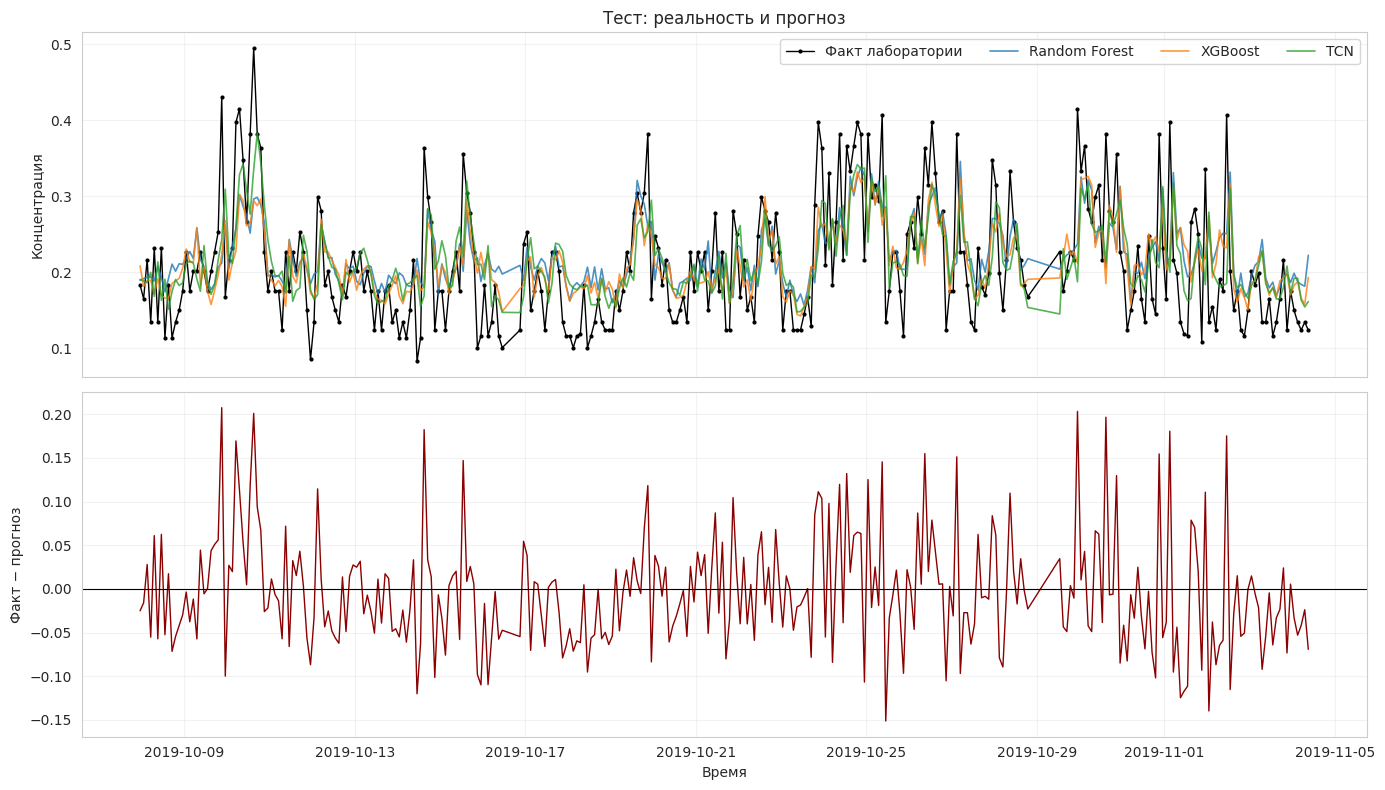

In [92]:
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True)
axes[0].plot(X_test_df.index,y_test,'k.-',ms=4,lw=1,label='Факт лаборатории')
for name,p in pred_test.items():
    axes[0].plot(X_test_df.index,p,lw=1.2,label=name,alpha=.8)
axes[0].set_ylabel('Концентрация');axes[0].set_title('Тест: реальность и прогноз');axes[0].legend(ncol=4)
axes[1].plot(X_test_df.index,y_test-pred_test[BEST_NAME],lw=1,color='darkred')
axes[1].axhline(0,color='black',lw=.8);axes[1].set_ylabel('Факт − прогноз');axes[1].set_xlabel('Время')
plt.tight_layout();plt.show()

### Направление изменений  во времени

Сравнение знака изменения концентрации относительно последнего доступного анализа.

In [93]:
last=y_last
prev=np.asarray(X_test_df['tgt_prev'],dtype=float)
trend_pred=2*last-prev
rows_dir={}
for name,p in {**pred_test,'Простое продолжение тренда':trend_pred}.items():
    acc,precision,n=direction_scores(y_test,p,last)
    rows_dir[name]={'Доля правильного направления':acc,'Точность ненулевых направлений':precision,'n изменений':n}
df_dir=fmt_table(rows_dir,'Прогноз')
display(df_dir)
df_dir.to_csv('results/direction.csv')

,Доля правильного направления,Точность ненулевых направлений,n изменений
Прогноз,,,
Random Forest,0.7170,0.7170,318.0
XGBoost,0.7044,0.7044,318.0
TCN,0.7013,0.7013,318.0
Простое продолжение тренда,0.3491,0.3675,318.0


### Диагностика остатков

Проверим автокорреляцию (Ljung–Box), нормальность (Jarque–Bera) и наличие ARCH-эффекта (ARCH-LM). Эти тесты нужны для понимания ограничений модели. Поскольку лабораторные замеры нерегулярны, автокорреляцию по номеру пробы нельзя автоматически трактовать как корреляцию на фиксированном числе часов.

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,Ljung–Box p,Jarque–Bera p,ARCH-LM p,Durbin–Watson
XGBoost,0.01788,0.0,0.09325,1.97107


Автокорреляция: обнаружена
Нормальность: отвергается
ARCH-эффект: не обнаружен


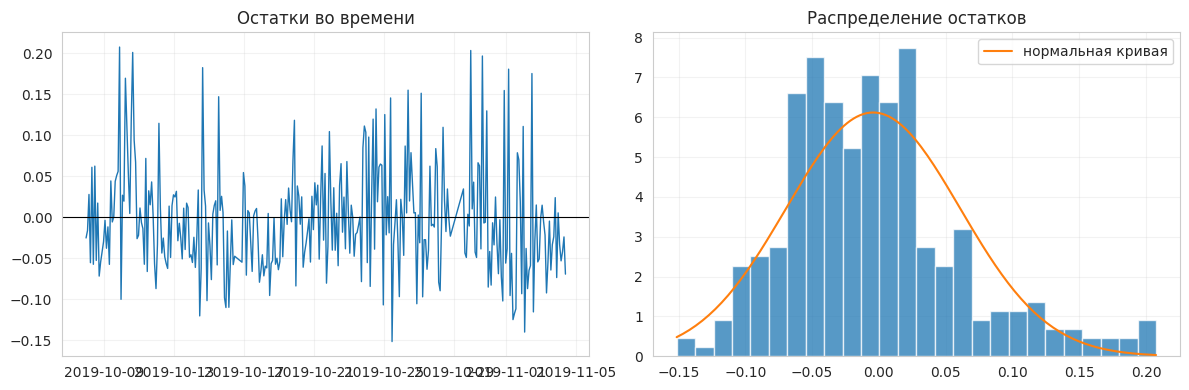

In [94]:
resid=y_test-pred_test[BEST_NAME]
lj=float(acorr_ljungbox(resid,lags=[10],return_df=True).lb_pvalue.iloc[0])
_,jb,_,_=jarque_bera(resid)
arch_p = float(het_arch(resid, nlags=10)[1])
dw=float(durbin_watson(resid))
df_res=pd.DataFrame([{'Ljung–Box p':lj,'Jarque–Bera p':jb,'ARCH-LM p':arch_p,'Durbin–Watson':dw}],index=[BEST_NAME])
display(df_res.round(5))
print('Автокорреляция:', 'обнаружена' if lj<.05 else 'не обнаружена на проверенных лагах')
print('Нормальность:', 'отвергается' if jb<.05 else 'не отвергается')
print('ARCH-эффект:', 'обнаружен' if arch_p<.05 else 'не обнаружен')
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(X_test_df.index,resid,lw=1);axes[0].axhline(0,color='black',lw=.8);axes[0].set_title('Остатки во времени')
axes[1].hist(resid,bins=26,density=True,alpha=.75);xx=np.linspace(resid.min(),resid.max(),150)
axes[1].plot(xx,stats.norm.pdf(xx,resid.mean(),max(resid.std(),1e-8)),label='нормальная кривая');axes[1].legend();axes[1].set_title('Распределение остатков')
plt.tight_layout();plt.show()

### Признаки важны для XGBoost

Permutation importance показывает, насколько возрастает MAE, если перемешать один столбец. SHAP распределяет вклад признаков в предсказание конкретной модели. Для интерпретации используем последний фолд CV, чтобы не обращаться к тестовым ответам.

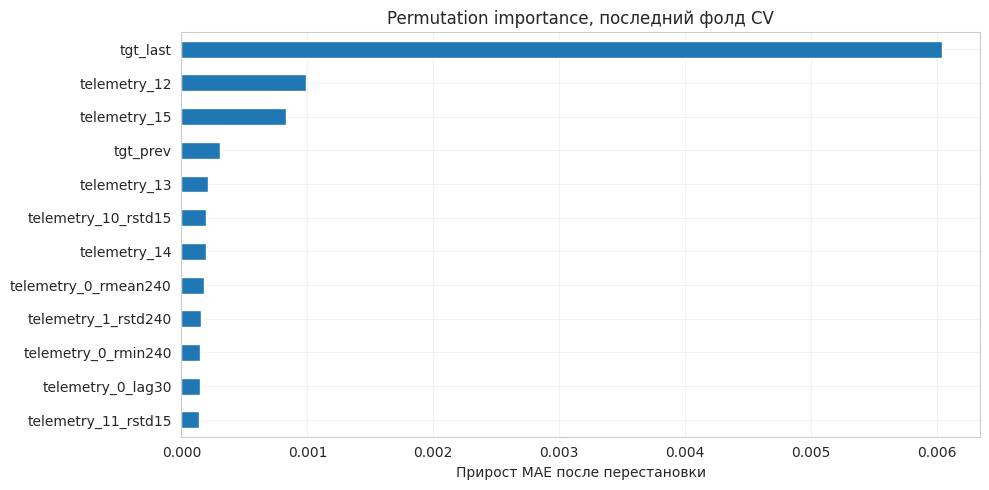

/tmp/ipykernel_1128/1456077727.py:13: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(values,shap_sample,max_display=12,show=False)


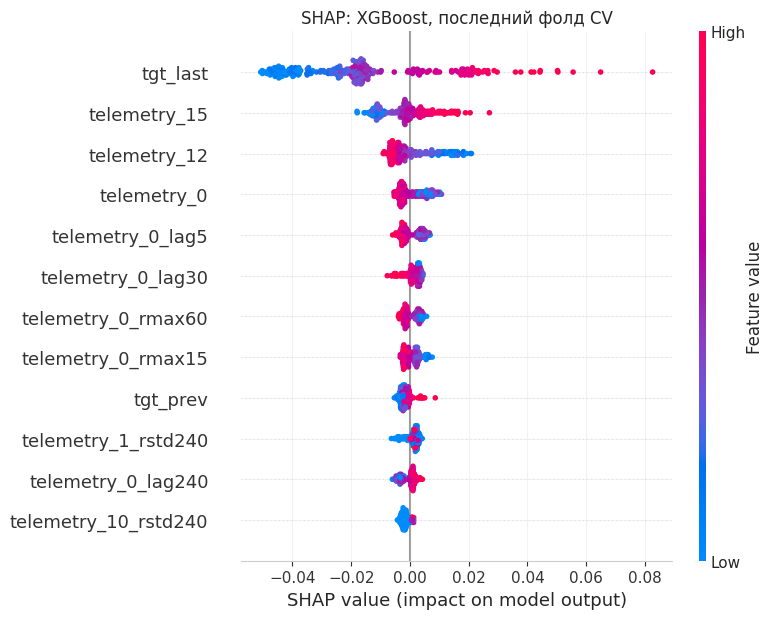

Наиболее важные признаки: {'tgt_last': 0.006, 'telemetry_12': 0.001, 'telemetry_15': 0.0008, 'tgt_prev': 0.0003, 'telemetry_13': 0.0002, 'telemetry_10_rstd15': 0.0002, 'telemetry_14': 0.0002}


In [95]:
tr,va=cal_folds[-1]
imputer_imp=MedianFiller().fit(X_train_df.iloc[tr],y_train[tr])
Xt=imputer_imp.transform(X_train_df.iloc[tr]);Xv=imputer_imp.transform(X_train_df.iloc[va])
interp_model=XGBRegressor(**XGB_PARAMS_FINAL).fit(Xt,y_train[tr])
per=permutation_importance(interp_model,Xv,y_train[va],scoring='neg_mean_absolute_error',n_repeats=5,random_state=RANDOM_STATE,n_jobs=1)
importance=pd.Series(per.importances_mean,index=Xv.columns).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(10,5))
importance.head(12).sort_values().plot.barh(ax=ax);ax.set_xlabel('Прирост MAE после перестановки');ax.set_title('Permutation importance, последний фолд CV')
plt.tight_layout();plt.show()
explainer=shap.TreeExplainer(interp_model)
shap_sample=Xv.iloc[:min(250,len(Xv))]
values=explainer.shap_values(shap_sample)
shap.summary_plot(values,shap_sample,max_display=12,show=False)
plt.title('SHAP: XGBoost, последний фолд CV');plt.tight_layout();plt.show()
print('Наиболее важные признаки:',importance.head(7).round(4).to_dict())

### AIC/BIC и вычислительная эффективность

In [96]:
# По информационным критериям нет корректных значений для этих трёх алгоритмов.
df_info = pd.DataFrame({
    'Модель': list(models),
    'AIC': ['не применяется'] * len(models),
    'BIC': ['не применяется'] * len(models),
}).set_index('Модель')
display(df_info)
print('AIC/BIC из первой ЛР пригодны для ARIMA/SARIMAX; здесь сравнение делаем по CV, тесту и времени.')

rows_time = []
for name, model in models.items():
    start = time.perf_counter()
    if name == 'TCN':
        _ = tcn_predict(model, Zte, tcn_center, tcn_scale)
    else:
        _ = model.predict(Xf_te)
    rows_time.append({
        'Модель': name,
        'Время финального обучения, с': train_times[name],
        'Инференс, мс на пробу': (time.perf_counter()-start)*1000/len(y_test),
    })
df_time = pd.DataFrame(rows_time).set_index('Модель')
display(df_time.round(3))
df_time.to_csv('results/efficiency.csv')


,AIC,BIC
Модель,,
Random Forest,не применяется,не применяется
XGBoost,не применяется,не применяется
TCN,не применяется,не применяется


AIC/BIC из первой ЛР пригодны для ARIMA/SARIMAX; здесь сравнение делаем по CV, тесту и времени.


,"Время финального обучения, с","Инференс, мс на пробу"
Модель,,
Random Forest,41.720,0.207
XGBoost,5.714,0.038
TCN,11.813,0.067


## Заключение
На данных телеметрии и нерегулярных лабораторных измерений обучены три метода : Random Forest, XGBoost и TCN. Для первых двух созданы лаги и скользящие характеристики, для TCN — многомерные окна